# Homework set 2

Please **submit this Jupyter notebook through Canvas** no later than **Thursday November 12**. **Submit the notebook file with your answers (as .ipynb file) and a pdf printout. The pdf version can be used by the teachers to provide feedback. On canvas there are hints about creating a nice pdf version.**

Before you hand in, please make sure the notebook runs, by running "Restart kernel and run all cells..." from the Kernel menu.

Homework is in **groups of two**, and you are expected to hand in original work. Work that is copied from another group will not be accepted.

# Exercise 0
Write down the names + student ID of the people in your group.

Timothy Bohm: 17068061

Meric Ikiz: 13940155

Run the following cell to import NumPy and Pyplot.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Exercise 1

In this exercise we consider interpolating a function $f$ on an interval $[a,b]$ with 5 regularly spaced points, including the end points.

## (a)

Let $a = 0.2$, $b=0.6$ (so spacing $0.1$ between the points), and let $f(x) = \cos(x)$.

Compute an interpolating polynomial $p(x)$ for $f$ by solving a linear system of equations using the monomial basis. Plot $p(x)$ and $f(x)$ (I suggest using the same plot and so that they are both visible). Also plot the interpolation error. Annotate your plots.

Then do the same with $a = 1000 \cdot \pi +0.2$ and $b = 1000\cdot \pi + 0.6$.

Describe briefly any notable differences in the resulting plots.


## (b)

Solve the problem with $a = 1000 \cdot \pi + 0.2$ and $b = 1000 \cdot \pi + 0.6$ again, but now using Newton polynomial basis function.

Compare with the second example of part (a).

## (c)

Explain what you see in the error graphs. What kind of errors are dominant in each of the error graphs? Explain the size of the dominant errors in each graph. N.B. a quantitative explanation is requested. Depending on the type of error you may want to have a look at the numbers in the computation of $p$ for finding your explanation.


# Exercise: non-standard interpolation method

We consider a non-standard interpolation method. It will be based on regularly spaced interpolation points $t_k = t_0 + k h$, where $k = 0, 1,2,3$ and $h$ is the spacing between the interpolation points.

The idea is to approximate $f(t_0 + \frac{1}{2} h)$ as follows
$$ \tag{1}
  f(t_0 + \frac{1}{2} h) \approx \hat{y} := a_0 f(t_0) + a_1 f(t_1) + a_2 f(t_2) + a_3 f(t_3)
$$
where the vector $a = [a_0, \ldots, a_3]$ is given by

In [4]:
a = np.array( [ 0.35, 0.825, -0.2, 0.025 ] )

## (a)

Let $f(x) = \exp(x)$. Formula (1) can now be used to approximate $y = \exp(\frac{1}{2} h)$, as a combination of $\exp(0)$, $\exp(h)$, $\exp(2h)$ and $\exp(3h)$.

Compute the error for $h = 1, \frac{1}{2}, (\frac{1}{2})^2, ..., (\tfrac{1}{2})^{10}$. Print a table of the results.


In [11]:
import pandas as pd # for table

def approximate_function(h, fx, a, t0=0):
    result = 0

    for i in range(4):
        ti = t0 + i * h
        result += a[i] * fx(ti)

    return result


fx = lambda x: np.exp(x) 
results = []

for k in range(11):
    h = 0.5 ** k
    estimate = approximate_function(h, fx, a)
    actual = fx(h/2)
    error = actual - estimate
    results.append({
        "h": h,
        "Estimate": estimate,
        "Exact": actual,
        "Error": error,
        "Absolute Error": abs(error)
    })
df = pd.DataFrame(results)
display(df)
    

,h,Estimate,Exact,Error,Absolute Error
0,1.000000,1.616910,1.648721,3.181156e-02,3.181156e-02
1,0.500000,1.278581,1.284025,5.444507e-03,5.444507e-03
2,0.250000,1.132502,1.133148,6.467380e-04,6.467380e-04
3,0.125000,1.064417,1.064494,7.728311e-05,7.728311e-05
4,0.062500,1.031734,1.031743,9.413270e-06,9.413270e-06
5,0.031250,1.015747,1.015748,1.160676e-06,1.160676e-06
6,0.015625,1.007843,1.007843,1.440718e-07,1.440718e-07
7,0.007812,1.003914,1.003914,1.794531e-08,1.794531e-08
8,0.003906,1.001955,1.001955,2.239172e-09,2.239172e-09
9,0.001953,1.000977,1.000977,2.796470e-10,2.796470e-10


## (b)

Does the error of (1) satisfy a power law in $h$, i.e. is it approximately of the form $C h^q$ ($q$ integer)? If so, for what $q$? If yes you can use a common sense approach to estimate $q$.

Power laws can be plotted nicely on a log-log scale. Make such a log-log plot. How can you read of $q$ from the plot? Draw a reference line corresponding to points that exactly satisfy a powerlaw with power $q$.

What power law would be satisfied if we had used standard Lagrange interpolation instead of the non-standard formula (1)?

(**N.B. For the rest of the course you need to know about this technique of analyzing or visualizing power laws using a log-log plot. In particular it is considered part of the material for the digital test.**)


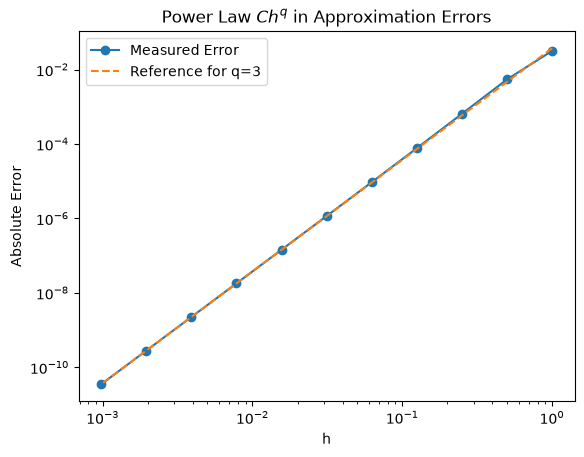

[2.54667767 3.07354816 3.06495638 3.03738531 3.01973087 3.0101048
 3.00510991 3.00256902 3.001287   3.00063476]
Dividing successive errors we can see that as h goes to infinity, q approaches 3.


In [26]:
h_values = df["h"].to_numpy()
abs_errors = df["Absolute Error"].to_numpy()

q = 3

plt.loglog(h_values, abs_errors, "o-", label="Measured Error")

C = abs_errors[-1] / h_values[-1]**q # using the last error to estimate the constant C
reference = C * h_values**q

plt.loglog(h_values, reference, "--", label=r"Reference for q=3")

plt.xlabel("h")
plt.ylabel("Absolute Error")
plt.title("Power Law $Ch^q$ in Approximation Errors")
plt.legend()
plt.show()


q_estimated = np.log2(abs_errors[:-1] / abs_errors[1:])
print(q_estimated)
print("Dividing successive errors we can see that as h approaches 0, estimated value of q approaches 3.")

Power law in h indicates $E(h) = Ch^q$ where $E(h)$ is the absolute error of the approximation, $h$ is spacing between interpolation points, $C$ is a constant and $q$ is the power describing the order of accuracy.

The error approximately behaves as $E(h) \approx Ch^q$ and when we halve $h$ we get $E(\frac{h}{2}) \approx C(\frac{h}{2})^q$. To find how much the error changes as we halve $h$ we divide the two errors $\frac{E(h)}{E(h/2)} \approx \frac{Ch^q}{C(h/2)^q}=2^q$. Taking the base 2 logarithm of both sides gives $q \approx \log_2\left(\frac{E(h)}{E(h/2)}\right)$. This is why we can use the successive absolute errors to see what value $q$ approaches to as in the line ```q_estimated = np.log2(abs_errors[:-1] / abs_errors[1:])```. We can just take the floor integer value of the last value. An alternative way to think about this is to think of the regular slope formula between two points for $log(h)$ and $log(E(h))$ which gives the same value $q=3$. 

To explain why $q$ corresponds to the slope, we take the logarithm of both sides of $E(h)$ and we get $logE(h) = log(Ch^q)$ and using logarithm laws we get $logE(h) = log(C) + qlog(h)$.

Comparing this to the equation of a straight line $y = b + mx$ we can see that the slope $m$ corresponds to q. So the slope of the line on a log-log plot gives us the power. 

Yes the errors satisfy a power law $Ch^q$ in h for $q=3$ as we can see from the reference line. The $C$ in the reference line was found from the last absolute error value as such: $C = \frac{\text{Absolute error of last element}}{(\text{Last used h})^q}$. 

In standard Lagrange interpolation, with $n$ distinct data points we can construct a unique interpolating polynomial of degree $n-1$ exactly. Since the function $e^x$ is infinitely differentiable, the interpolation error is given by below equation where $\theta$ is some point within the interpolation interval $0 < \theta < 3h$.
$$  
f(x)-p_{n-1}(x)=\frac{f^{(n)}(\theta)}{n!}\prod_{i=0}^{n-1}(x-x_i)  
$$ 

We have four interpolation points so $n=4$ and the points are 0 ,h, 2h, 3h Evaluating at $x=h/2$, we get

$$  
f(h/2)-p_3(h/2)=\frac{f^{(4)}(\theta)}{4!}  
\left(\frac h2\right)  
\left(-\frac h2\right)  
\left(-\frac{3h}{2}\right)  
\left(-\frac{5h}{2}\right).  
$$

Simplfying and taking the nth derivative and plugging in $\theta$ we get:

$$  
f(h/2)-p_3(h/2)=-\frac{5}{128}e^\theta h^4.  
$$

As $h$ approaches zero, $\theta$ also approaches zero, so $e^\theta$ approaches 1. Therefore, the absolute error is approximately

$$  
E(h)\approx\frac{5}{128}h^4.  
$$

We can express the error order using Big-O notation as

$$  
E(h)=O(h^4).  
$$

This means the error is bounded by a constant times $h^4$ for sufficiently small $h$. The error here also approximately follows a power law $Ch^q$, but with $q=4$ instead of $q=3$.
